# Mini-Projet Séries Temporelles — Partie 7 (bonus)
## Extensions : variables exogènes, corrélation dynamique AAPL–QQQ, événements et ruptures

### Prérequis : reprise du socle de la partie 6
Les extensions 7.1 à 7.3 utilisent le **même protocole d'évaluation** que la partie 6 (mêmes origines de test, mêmes métriques, mêmes modèles de référence). Pour que ce notebook soit exécutable seul, les cellules ci-dessous **recalculent le socle de la partie 6** (configuration, utilitaires, modèles économétriques et réseaux, fonction `evaluate_all`) ; elles sont identiques à celles du notebook de la partie 6, dont on a seulement retiré les graphiques et les commentaires.

In [105]:
# === Configuration & imports ==========================================================
# Pourquoi en premier : tout ce qui conditionne la reproductibilité (graine, versions, chemins, hyper-paramètres)
# est centralisé ici pour qu'un correcteur puisse relancer l'étude à l'identique.
import os, re, json, time, warnings, platform, contextlib, io
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"       # moins de messages TensorFlow
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"       # calculs plus reproductibles d'une machine à l'autre
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
from scipy import stats
from scipy.optimize import minimize

import statsmodels, scipy, sklearn
from statsmodels.tsa.stattools import adfuller, grangercausalitytests
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.api import VAR
from statsmodels.tsa.regime_switching.markov_regression import MarkovRegression
from arch import arch_model
import arch as arch_pkg

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# ---- Paramètres généraux (modifiables) -----------------------------------------------
QUICK_RUN = False                         # True = test rapide (3 époques, 1 graine) : sert seulement à vérifier que tout tourne
SEED      = 42
H         = 10                            # horizon maximal de prévision (énoncé : h = 5 à 10)
ALPHA     = 0.05                          # niveau des intervalles de prédiction (95 %)
CSV_PATH  = "../data/data_aapl_qqq.csv"   # même fichier que l'équipe
EXOG_PATH = "../data/data_exog.csv"       # cache VIX / taux 10 ans (partie 7.1) ; à joindre à l'archive pour un usage hors-ligne
NEWS_PATH = "../data/news.csv"            # corpus d'actualités OPTIONNEL (colonnes : date, headline) — partie 7.3
OUT_DIR   = "../outputs"
for d in (OUT_DIR, "../data"): os.makedirs(d, exist_ok=True)

# ---- Hyper-paramètres des réseaux (mêmes principes que la partie 4) -------------------
CFG = dict(dropout=0.2, lr=1e-3, batch=32, max_epochs=80, patience=8, val_frac=0.15, n_seeds=3)
if QUICK_RUN: CFG.update(max_epochs=3, patience=2, n_seeds=1)

np.random.seed(SEED); keras.utils.set_random_seed(SEED); tf.get_logger().setLevel("ERROR")
try: tf.config.experimental.enable_op_determinism()
except Exception: pass
sns.set_theme(style="whitegrid"); plt.rcParams["figure.figsize"] = (12, 4.5)

print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__, "| statsmodels", statsmodels.__version__,
      "| arch", arch_pkg.__version__, "| scikit-learn", sklearn.__version__, "| tensorflow", tf.__version__)
print("QUICK_RUN =", QUICK_RUN, "| H =", H, "| niveau des intervalles =", f"{100*(1-ALPHA):.0f} %", "|", CFG)

Python 3.13.16 | numpy 2.1.3 | pandas 2.2.3 | statsmodels 0.15.0 | arch 8.0.0 | scikit-learn 1.6.1 | tensorflow 2.21.0
QUICK_RUN = False | H = 10 | niveau des intervalles = 95 % | {'dropout': 0.2, 'lr': 0.001, 'batch': 32, 'max_epochs': 80, 'patience': 8, 'val_frac': 0.15, 'n_seeds': 3}


In [106]:
# === Étape 0b — rechargement des données de l'équipe (prix ET volumes) ================
# Pourquoi : notebook autonome ; mêmes formules que l'équipe (rendement log, MA20, volatilité 20 j, split chronologique 90/10).
def load_prices(csv_path=CSV_PATH):
    """Lit le CSV écrit par yf.download(...).to_csv (3 lignes d'en-tête). Renvoie prix ajustés et volumes."""
    if os.path.exists(csv_path):
        raw = pd.read_csv(csv_path, header=[0, 1], index_col=0)
        raw.index = pd.to_datetime(raw.index, errors="coerce")
        raw = raw[raw.index.notna()].astype(float)
        px, vol, src = raw["Adj Close"], raw["Volume"], f"CSV local : {csv_path}"
    else:
        import yfinance as yf
        data = yf.download(["AAPL", "QQQ"], start="2019-01-01", end="2026-10-01", auto_adjust=False, progress=False)
        px, vol, src = data["Adj Close"], data["Volume"], "yfinance (téléchargement direct)"
    return px[["AAPL", "QQQ"]].sort_index(), vol[["AAPL", "QQQ"]].sort_index(), src

prices, volume, source = load_prices()
assert prices.index.is_monotonic_increasing and not prices.index.duplicated().any() and not prices.isna().any().any()
returns = np.log(prices / prices.shift(1)).dropna()
dataset = pd.DataFrame({
    "AAPL": prices["AAPL"], "QQQ": prices["QQQ"],
    "AAPL_Return": returns["AAPL"], "QQQ_Return": returns["QQQ"],
    "AAPL_MA20": prices["AAPL"].rolling(20).mean(),
    "AAPL_Volatility20": returns["AAPL"].rolling(20).std()})
split_index = int(len(dataset) * 0.90)
train, test = dataset.iloc[:split_index].copy(), dataset.iloc[split_index:].copy()
print("Source :", source)
print(f"Période : {dataset.index[0].date()} → {dataset.index[-1].date()} | n = {len(dataset)} | train = {len(train)} | test = {len(test)}")
print("✔ identique au notebook de l'équipe (1947 / 1752 / 195)" if (len(dataset), len(train), len(test)) == (1947, 1752, 195)
      else "⚠ dimensions différentes de celles du notebook de l'équipe (1947 / 1752 / 195) : vérifier le fichier CSV")

Source : yfinance (téléchargement direct)
Période : 2019-01-02 → 2026-09-30 | n = 1947 | train = 1752 | test = 195
✔ identique au notebook de l'équipe (1947 / 1752 / 195)


In [107]:
# === Utilitaires communs (identiques à la partie 4 : mêmes métriques, mêmes tests) ====
def fit_scaler(F, cut):
    """Moyenne / écart-type calculés sur les lignes [0:cut] SEULEMENT (= information disponible à l'époque)."""
    return F[:cut].mean(axis=0), F[:cut].std(axis=0, ddof=0)

def price_metrics(y, yhat):
    e = np.asarray(y) - np.asarray(yhat)
    return dict(MSE=np.mean(e**2), RMSE=np.sqrt(np.mean(e**2)), MAE=np.mean(np.abs(e)), MAPE=100 * np.mean(np.abs(e / np.asarray(y))))

def diebold_mariano(e_model, e_ref, h=1, power=2):
    """DM (Harvey-Leybourne-Newbold). d_t = |e_model|^p − |e_ref|^p ; DM<0 ⇒ le modèle est meilleur que la référence.
    Pour un horizon h > 1 les erreurs se chevauchent : la variance est corrigée par h−1 autocovariances (HAC)."""
    d = np.abs(np.asarray(e_model))**power - np.abs(np.asarray(e_ref))**power
    T, dbar = len(d), d.mean()
    gam = lambda k: np.sum((d[k:] - dbar) * (d[:T - k] - dbar)) / T
    var = gam(0) + 2 * sum(gam(k) for k in range(1, h))
    if var <= 1e-18: return np.nan, np.nan
    dm = dbar / np.sqrt(var / T) * np.sqrt((T + 1 - 2*h + h*(h - 1) / T) / T)
    return float(dm), float(2 * (1 - stats.t.cdf(abs(dm), df=T - 1)))

def verdict(dm, p):
    if np.isnan(p): return "référence"
    if p < 0.05: return "significativement MEILLEUR" if dm < 0 else "significativement MOINS BON"
    return "différence non significative"

def best_config_from_part4():
    """Reprend les (fenêtre, unités) retenus par la validation walk-forward de la partie 4."""
    p = f"{OUT_DIR}/walkforward_grid_part4.csv"
    if os.path.exists(p):
        g = pd.read_csv(p); b = g.loc[g.groupby("modele")["ratio_moy"].idxmin()].set_index("modele")
        return {k: (int(r.fenetre), int(r.unites)) for k, r in b.iterrows()}, "partie 4 (walkforward_grid_part4.csv)"
    return {"LSTM": (10, 16), "GRU": (10, 16)}, "valeurs par défaut (fichier de la partie 4 introuvable)"
BEST, best_src = best_config_from_part4()
print("Hyper-paramètres des réseaux repris de la", best_src, ":", BEST)

Hyper-paramètres des réseaux repris de la partie 4 (walkforward_grid_part4.csv) : {'GRU': (10, 32), 'LSTM': (20, 32)}


In [108]:
# === Tableaux de bord communs : variables, origines, valeurs réelles ===================
FEATURES_BASE = ["AAPL_Return", "QQQ_Return", "AAPL_Volatility20"]          # colonne 0 = cible
feat = dataset[FEATURES_BASE].dropna()
dates, T = feat.index, len(feat)
train_end = train.index[-1]
cut_final = int((dates <= train_end).sum())                                 # nb de lignes de la période d'apprentissage
F = feat.values.astype("float64")
PX = dataset.loc[dates, "AAPL"].values                                      # prix ajusté AAPL aligné sur `feat`

ORIG = np.arange(cut_final - 1, T - H)                                      # origines t du test avec 10 jours observés après
ORIG_EXT = np.append(ORIG, T - 1)                                           # + origine « réelle » : prévision après la dernière date
n_o = len(ORIG)
P_o = PX[ORIG]
P_fut = np.stack([PX[ORIG + h] for h in range(1, H + 1)], axis=1)           # prix réels à t+1 … t+10  (n_o, H)
R_act = np.log(P_fut / P_o[:, None])                                        # rendements cumulés réels
z975 = stats.norm.ppf(1 - ALPHA / 2)
print(f"lignes : {T} | train : {cut_final} | origines de test : {n_o} (du {dates[ORIG[0]].date()} au {dates[ORIG[-1]].date()}) | horizons : 1…{H}")

MODELS = {}                  # nom → dict(R, lo, hi, R_fwd, lo_fwd, hi_fwd, fit_time, n_params, interval)
REF = "ARIMA(0,1,0) / naïf"
REF2 = "Marche aléatoire log + dérive"      # référence plus exigeante : un modèle qui ne fait que reproduire la dérive bat le naïf sans rien apprendre
def register(name, R_ext, lo_ext, hi_ext, fit_time, n_params, interval):
    """Range les prévisions : les n_o premières lignes = test ; la dernière = prévision hors échantillon (après la dernière date)."""
    MODELS[name] = dict(R=R_ext[:-1], lo=lo_ext[:-1], hi=hi_ext[:-1], R_fwd=R_ext[-1], lo_fwd=lo_ext[-1], hi_fwd=hi_ext[-1],
                        fit_time=fit_time, n_params=n_params, interval=interval)

lignes : 1927 | train : 1732 | origines de test : 186 (du 2025-12-18 au 2026-09-16) | horizons : 1…10


In [109]:
# === ARIMA(0,1,0) (modèle de l'équipe) et marche aléatoire log + dérive ================
t0 = time.perf_counter(); arima_fit = ARIMA(train["AAPL"].values, order=(0, 1, 0)).fit(); t_arima = time.perf_counter() - t0
sigma2 = float(arima_fit.params[-1])                                        # variance des variations de prix (en $²)
h_idx = np.arange(1, H + 1)

# Contrôle : mon intervalle analytique = celui de statsmodels (get_forecast)
ci = arima_fit.get_forecast(steps=H).conf_int(alpha=ALPHA)
mine = np.c_[train["AAPL"].values[-1] - z975*np.sqrt(sigma2*h_idx), train["AAPL"].values[-1] + z975*np.sqrt(sigma2*h_idx)]
print("contrôle intervalle ARIMA — écart max avec statsmodels :", float(np.abs(np.asarray(ci) - mine).max()), "(≈ 0)")

P_ext = PX[ORIG_EXT]
R0 = np.zeros((len(ORIG_EXT), H))
register(REF, R0, np.maximum(P_ext[:, None] - z975*np.sqrt(sigma2*h_idx)[None, :], 1e-6), P_ext[:, None] + z975*np.sqrt(sigma2*h_idx)[None, :],
         t_arima, 1, "analytique (σ constant en $)")

drift, sd_r = F[:cut_final, 0].mean(), F[:cut_final, 0].std()
R_rw = np.outer(np.ones(len(ORIG_EXT)), drift * h_idx)
sd_rw = sd_r * np.sqrt(h_idx)
register("Marche aléatoire log + dérive", R_rw, P_ext[:, None]*np.exp(R_rw - z975*sd_rw[None, :]), P_ext[:, None]*np.exp(R_rw + z975*sd_rw[None, :]),
         0.0, 2, "analytique (σ constant des rendements)")
print(f"dérive d'apprentissage : {drift:.6f}/jour | écart-type des rendements : {sd_r:.5f}")

contrôle intervalle ARIMA — écart max avec statsmodels : 3.467448550509289e-12 (≈ 0)
dérive d'apprentissage : 0.001118/jour | écart-type des rendements : 0.01939


In [110]:
# === VAR sur les rendements (AAPL, QQQ) : prévision récursive + intervalle analytique ==
def fit_var(p):
    t0 = time.perf_counter()
    res = VAR(train[["AAPL_Return", "QQQ_Return"]].dropna()).fit(p)          # même jeu que l'équipe
    return res, time.perf_counter() - t0

def var_forecasts(res, p):
    """Rendements AAPL cumulés prévus à chaque origine (paramètres figés, information jusqu'à l'origine) + écart-type cumulé analytique."""
    R = np.zeros((len(ORIG_EXT), H))
    for i, o in enumerate(ORIG_EXT):
        R[i] = np.cumsum(res.forecast(F[o - p + 1:o + 1, :2], steps=H)[:, 0])
    Phi = res.ma_rep(maxn=H); Su = np.asarray(res.sigma_u)                   # Φ_0 = I, Φ_1, …
    var_cum = np.zeros(H)
    for h in range(1, H + 1):                                               # erreur cumulée = Σ_k C_{h-k} u_{t+k}, C_m = Φ_0+…+Φ_m
        for k in range(1, h + 1):
            C = Phi[:h - k + 1].sum(axis=0); var_cum[h - 1] += (C @ Su @ C.T)[0, 0]
    return R, np.sqrt(var_cum)

sel = VAR(train[["AAPL_Return", "QQQ_Return"]].dropna()).select_order(maxlags=20).selected_orders
p_aic, p_bic = int(sel["aic"]), max(int(sel["bic"]), 1)
print("ordre VAR : AIC =", p_aic, "| BIC =", p_bic)
var_specs = [(p_aic, f"VAR({p_aic}) (AIC)")] + ([(p_bic, f"VAR({p_bic}) (BIC)")] if p_bic != p_aic else [])
for p, name in var_specs:
    res_v, t_v = fit_var(p)
    R_v, sd_v = var_forecasts(res_v, p)
    print(f"{name} : écart-type 1 pas = {sd_v[0]:.5f} (attendu √Σu[0,0] = {np.sqrt(np.asarray(res_v.sigma_u)[0, 0]):.5f}) | h=10 : {sd_v[-1]:.5f}")
    register(name, R_v, P_ext[:, None]*np.exp(R_v - z975*sd_v[None, :]), P_ext[:, None]*np.exp(R_v + z975*sd_v[None, :]),
             t_v, 2 * (1 + 2 * p), "analytique (variance cumulée VAR)")

ordre VAR : AIC = 9 | BIC = 1
VAR(9) (AIC) : écart-type 1 pas = 0.01912 (attendu √Σu[0,0] = 0.01912) | h=10 : 0.05617
VAR(1) (BIC) : écart-type 1 pas = 0.01935 (attendu √Σu[0,0] = 0.01935) | h=10 : 0.05722


In [111]:
# === GARCH(1,1) de l'équipe (normal, moyenne constante) : intervalles à variance conditionnelle ======
t0 = time.perf_counter()
garch_res = arch_model(train["AAPL_Return"].dropna() * 100, mean="Constant", vol="GARCH", p=1, q=1).fit(disp="off")
t_garch = time.perf_counter() - t0
Pg = garch_res.params; mu_g, om, al, be = Pg["mu"], Pg["omega"], Pg["alpha[1]"], Pg["beta[1]"]
print(f"GARCH(1,1) : mu={mu_g:.4f}% omega={om:.4f} alpha={al:.4f} beta={be:.4f} | persistance={al + be:.4f}")

# Filtrage sur toute la série avec les paramètres figés du train (aucune fuite) → σ_{t+1} connu dès t
all_ret_pct = returns["AAPL"] * 100
garch_fixed = arch_model(all_ret_pct, mean="Constant", vol="GARCH", p=1, q=1).fix(garch_res.params)
sig_next = garch_fixed.conditional_volatility.shift(-1)
sig_next.iloc[-1] = float(np.sqrt(garch_fixed.forecast(horizon=1).variance.iloc[-1, 0]))   # dernier jour : prévision à 1 pas
sig_next_al = sig_next.reindex(dates).values                                               # σ_{t+1} (%), aligné sur `feat`

ab, sbar2 = al + be, om / (1 - al - be)                                      # persistance et variance inconditionnelle (%²)
sig2_1 = sig_next_al[ORIG_EXT]**2
Ev = sbar2 + (ab ** (h_idx - 1))[None, :] * (sig2_1[:, None] - sbar2)         # E[σ²_{t+j} | t], j = 1…H
sd_g = np.sqrt(np.cumsum(Ev, axis=1)) / 100                                  # écart-type du rendement cumulé (en log)
R_g = np.outer(np.ones(len(ORIG_EXT)), mu_g / 100 * h_idx)
register("GARCH(1,1)", R_g, P_ext[:, None]*np.exp(R_g - z975*sd_g), P_ext[:, None]*np.exp(R_g + z975*sd_g),
         t_garch, 4, "analytique (variance conditionnelle)")

# Contrôle de l'approximation gaussienne : simulation de Monte-Carlo à la dernière date
sim = garch_fixed.forecast(horizon=H, method="simulation", simulations=4000).simulations.values[-1]   # (4000, H) rendements en %
cum = sim.cumsum(axis=1) / 100
print("contrôle par simulation (dernière date) — écart-type du rendement cumulé :")
print("  h :", [1, 5, 10], "| analytique :", [round(float(sd_g[-1, h-1]), 4) for h in (1, 5, 10)], "| simulé :", [round(float(cum[:, h-1].std()), 4) for h in (1, 5, 10)])
print("  quantiles 2.5 %/97.5 % à h=10 → simulé :", np.round(np.quantile(cum[:, -1], [0.025, 0.975]), 4),
      "| gaussien :", np.round(np.array([-1, 1]) * z975 * sd_g[-1, -1] + R_g[-1, -1], 4))

GARCH(1,1) : mu=0.1753% omega=0.1577 alpha=0.1044 beta=0.8505 | persistance=0.9549
contrôle par simulation (dernière date) — écart-type du rendement cumulé :
  h : [1, 5, 10] | analytique : [0.0157, 0.0357, 0.0515] | simulé : [0.0157, 0.036, 0.0522]
  quantiles 2.5 %/97.5 % à h=10 → simulé : [-0.0888  0.1189] | gaussien : [-0.0833  0.1184]


In [112]:
# === Réseaux multi-sorties : fenêtres, modèle, entraînement, calibration conformale ===
def make_windows_h(Fs, W, H):
    """X[i] = lignes (o-W+1 … o) ; Y[i] = rendements standardisés des H jours suivants (o+1 … o+H)."""
    origins = np.arange(W - 1, Fs.shape[0] - H)
    X = np.stack([Fs[o - W + 1:o + 1] for o in origins])
    Y = np.stack([Fs[o + 1:o + H + 1, 0] for o in origins])
    return X, Y, origins

def build_model_h(kind, window, n_feat, units):
    Rnn = layers.LSTM if kind == "LSTM" else layers.GRU
    m = keras.Sequential([layers.Input(shape=(window, n_feat)), Rnn(units), layers.Dropout(CFG["dropout"]), layers.Dense(H)])
    m.compile(optimizer=keras.optimizers.Adam(CFG["lr"]), loss=keras.losses.Huber(delta=1.0))
    return m

def fit_one_h(kind, X, Y, window, units, seed):
    keras.utils.set_random_seed(seed)
    model = build_model_h(kind, window, X.shape[2], units)
    n_val = max(int(len(X) * CFG["val_frac"]), 1)
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=CFG["patience"], restore_best_weights=True)
    hist = model.fit(X[:-n_val], Y[:-n_val], validation_data=(X[-n_val:], Y[-n_val:]), epochs=CFG["max_epochs"],
                     batch_size=CFG["batch"], shuffle=True, callbacks=[es], verbose=0)
    return model, hist.history

def conformal_q(abs_err, alpha=ALPHA):
    """Quantile conformal (split) par horizon : ⌈(n+1)(1−α)⌉-ième plus petite erreur absolue."""
    n = abs_err.shape[0]; k = min(int(np.ceil((n + 1) * (1 - alpha))), n)
    return np.sort(abs_err, axis=0)[k - 1]

def train_multi(name, kind, Fmat, interval="conformal split"):
    """Entraîne n_seeds réseaux (train seulement) ; prévisions de test, calibration conformale et prévision hors échantillon."""
    W, units = BEST[kind]
    mu_, sd_ = fit_scaler(Fmat, cut_final); Fs_ = (Fmat - mu_) / sd_
    X, Y, orig = make_windows_h(Fs_, W, H)
    tr = orig <= cut_final - 1 - H                                   # les H cibles sont toutes dans le train
    te = np.isin(orig, ORIG); assert te.sum() == n_o
    Xtr, Ytr, Xte = X[tr], Y[tr], X[te]
    n_val = max(int(len(Xtr) * CFG["val_frac"]), 1)
    X_last = Fs_[-W:][None, :, :]                                    # dernière fenêtre disponible → prévision hors échantillon
    P_te, P_val, P_fwd, n_par, hist0 = [], [], [], None, None
    t0 = time.perf_counter()
    for i in range(CFG["n_seeds"]):
        model, h_ = fit_one_h(kind, Xtr, Ytr, W, units, SEED + i)
        P_te.append(model.predict(Xte, verbose=0)); P_val.append(model.predict(Xtr[-n_val:], verbose=0)); P_fwd.append(model.predict(X_last, verbose=0)[0])
        if i == 0: n_par, hist0 = model.count_params(), h_
        keras.backend.clear_session()
    fit_time = time.perf_counter() - t0
    cum = lambda Z: np.cumsum(Z * sd_[0] + mu_[0], axis=-1)           # standardisé → rendements → cumul
    R_te, R_val, R_fwd = cum(np.mean(P_te, 0)), cum(np.mean(P_val, 0)), cum(np.mean(P_fwd, 0))
    q = conformal_q(np.abs(cum(Ytr[-n_val:]) - R_val))                # erreurs de calibration par horizon
    R_ext = np.vstack([R_te, R_fwd[None, :]])
    register(name, R_ext, P_ext[:, None]*np.exp(R_ext - q[None, :]), P_ext[:, None]*np.exp(R_ext + q[None, :]), fit_time, n_par, interval)
    print(f"{name:12s} W={W:2d} unités={units:2d} | {n_par:5d} paramètres | {fit_time:5.0f} s ({CFG['n_seeds']} graines) | demi-largeur conformale h=1/5/10 : {np.round(q[[0, 4, 9]], 4)}")
    return hist0

# Variable GARCH (volatilité de J+1 prévue, sans fuite) pour les modèles hybrides — même construction qu'en partie 4
F_h = np.column_stack([F, sig_next_al])
assert not np.isnan(F_h).any()
HIST = {}
for kind in ["LSTM", "GRU"]:
    HIST[kind] = train_multi(kind, kind, F)
for kind in ["LSTM", "GRU"]:
    HIST[f"{kind}+GARCH"] = train_multi(f"{kind}+GARCH", kind, F_h)

LSTM         W=20 unités=32 |  4938 paramètres |    29 s (3 graines) | demi-largeur conformale h=1/5/10 : [0.0407 0.1012 0.1213]
GRU          W=10 unités=32 |  3882 paramètres |    30 s (3 graines) | demi-largeur conformale h=1/5/10 : [0.0415 0.1044 0.1198]
LSTM+GARCH   W=20 unités=32 |  5066 paramètres |    29 s (3 graines) | demi-largeur conformale h=1/5/10 : [0.0401 0.1064 0.1226]
GRU+GARCH    W=10 unités=32 |  3978 paramètres |    38 s (3 graines) | demi-largeur conformale h=1/5/10 : [0.0406 0.1055 0.1203]


In [113]:
def evaluate_all(models):
    """Une ligne par (modèle, horizon) : métriques de prix, de rendement cumulé, Diebold-Mariano et qualité des intervalles."""
    rows, ref, ref2 = [], models[REF], models[REF2]
    for name, m in models.items():
        for h in range(1, H + 1):
            R, y = m["R"][:, h - 1], P_fut[:, h - 1]; Ph = P_o * np.exp(R)
            row = dict(modele=name, h=h, **price_metrics(y, Ph))
            e_c = R_act[:, h - 1] - R
            row["RMSE_cum"], row["MAE_cum"] = float(np.sqrt(np.mean(e_c**2))), float(np.mean(np.abs(e_c)))
            if name != REF:
                row["DM_prix"], row["p_DM_prix"] = diebold_mariano(y - Ph, y - P_o * np.exp(ref["R"][:, h - 1]), h=h)
                row["DM_cum"], row["p_DM_cum"] = diebold_mariano(e_c, R_act[:, h - 1] - ref["R"][:, h - 1], h=h)
            else:
                row.update(DM_prix=np.nan, p_DM_prix=np.nan, DM_cum=np.nan, p_DM_cum=np.nan)
            if name not in (REF, REF2):
                row["DM_vs_derive"], row["p_DM_vs_derive"] = diebold_mariano(e_c, R_act[:, h - 1] - ref2["R"][:, h - 1], h=h)
            else:
                row["DM_vs_derive"], row["p_DM_vs_derive"] = np.nan, np.nan
            lo, hi = m["lo"][:, h - 1], m["hi"][:, h - 1]
            ins = (y >= lo) & (y <= hi)
            wink = (hi - lo) + (2 / ALPHA) * np.maximum(lo - y, 0) + (2 / ALPHA) * np.maximum(y - hi, 0)
            row.update(couverture=float(ins.mean()), largeur=float(np.mean(hi - lo)), winkler=float(np.mean(wink)))
            rows.append(row)
    return pd.DataFrame(rows)

res = evaluate_all(MODELS)
SHOW_H = [1, 5, 10]
cols = ["MSE", "RMSE", "MAE", "MAPE", "RMSE_cum", "p_DM_cum", "p_DM_vs_derive", "couverture", "largeur", "winkler"]
summary_all = res[res.h.isin(SHOW_H)].set_index(["modele", "h"])[cols].unstack("h")
summary_all = summary_all.reindex(list(MODELS))                                       # ordre de création des modèles
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 50)
print("TABLEAU RÉCAPITULATIF UNIQUE (prix en $ ; RMSE_cum = rendement cumulé ; p_DM_cum = Diebold-Mariano contre ARIMA(0,1,0))")
display(summary_all[["MSE", "RMSE", "MAE", "MAPE"]].round(3))
display(summary_all[["RMSE_cum", "p_DM_cum", "p_DM_vs_derive"]].round(4))
print("p_DM_cum : Diebold-Mariano contre ARIMA(0,1,0) ; p_DM_vs_derive : contre la marche aléatoire log + dérive (référence plus exigeante).")
display(summary_all[["couverture", "largeur", "winkler"]].round(3))

TABLEAU RÉCAPITULATIF UNIQUE (prix en $ ; RMSE_cum = rendement cumulé ; p_DM_cum = Diebold-Mariano contre ARIMA(0,1,0))


MSE                     RMSE                    MAE                  MAPE              
h                                  1        5        10     1       5       10     1      5       10     1      5      10
modele                                                                                                                   
ARIMA(0,1,0) / naïf            23.765  125.129  231.535  4.875  11.186  15.216  3.474  8.846  12.748  1.208  3.056  4.363
Marche aléatoire log + dérive  23.655  122.366  220.721  4.864  11.062  14.857  3.456  8.654  12.387  1.203  3.006  4.286
VAR(9) (AIC)                   23.671  120.582  214.239  4.865  10.981  14.637  3.533  8.839  12.503  1.233  3.063  4.317
VAR(1) (BIC)                   23.657  123.772  221.606  4.864  11.125  14.886  3.490  8.684  12.392  1.215  3.017  4.291
GARCH(1,1)                     23.684  123.112  223.921  4.867  11.096  14.964  3.455  8.590  12.331  1.204  2.994  4.294
LSTM                           23.735  125.755  230.968  4.872  11.214  15.198  3.451  8.669  12.506  1.202  3.017  4.340
GRU                            23.731  123.169  224.856  4.871  11.098  14.995  3.468  8.623  12.326  1.208  3.000  4.278
LSTM+GARCH                     23.777  127.945  236.232  4.876  11.311  15.370  3.454  8.747  12.538  1.203  3.045  4.353
GRU+GARCH                      23.689  123.988  225.423  4.867  11.135  15.014  3.460  8.649  12.337  1.205  3.009  4.281

RMSE_cum                 p_DM_cum                 p_DM_vs_derive                
h                                   1       5       10       1       5       10             1       5       10
modele                                                                                                        
ARIMA(0,1,0) / naïf             0.0168  0.0383  0.0521      NaN     NaN     NaN            NaN     NaN     NaN
Marche aléatoire log + dérive   0.0167  0.0379  0.0508   0.6240  0.6134  0.6346            NaN     NaN     NaN
VAR(9) (AIC)                    0.0168  0.0376  0.0502   0.8719  0.6118  0.5257         0.7899  0.8192  0.6255
VAR(1) (BIC)                    0.0168  0.0381  0.0509   0.9426  0.7942  0.6802         0.8260  0.0106  0.5617
GARCH(1,1)                      0.0167  0.0380  0.0512   0.8163  0.8093  0.8263         0.8249  0.8236  0.8177
LSTM                            0.0168  0.0383  0.0519   0.9028  0.9744  0.9497         0.5433  0.2414  0.2493
GRU                             0.0168  0.0380  0.0513   0.9743  0.7715  0.8028         0.5405  0.5751  0.5395
LSTM+GARCH                      0.0168  0.0387  0.0525   0.9942  0.7324  0.9135         0.3984  0.0792  0.1149
GRU+GARCH                       0.0168  0.0381  0.0514   0.8293  0.8782  0.8159         0.7522  0.3564  0.4594

p_DM_cum : Diebold-Mariano contre ARIMA(0,1,0) ; p_DM_vs_derive : contre la marche aléatoire log + dérive (référence plus exigeante).


couverture               largeur                 winkler                 
h                                     1      5      10      1       5       10      1       5        10
modele                                                                                                 
ARIMA(0,1,0) / naïf                0.790  0.742  0.769  10.914  24.404  34.513  37.732  84.107  102.185
Marche aléatoire log + dérive      0.962  0.957  0.989  21.763  48.929  69.668  27.431  54.720   70.162
VAR(9) (AIC)                       0.968  0.962  0.989  21.459  45.792  63.815  26.933  50.124   64.549
VAR(1) (BIC)                       0.973  0.946  0.978  21.717  45.977  65.037  27.109  54.852   67.497
GARCH(1,1)                         0.935  0.946  0.978  19.102  43.509  62.820  27.661  51.694   65.878
LSTM                               0.978  0.984  0.984  23.337  58.363  70.519  28.344  60.189   72.225
GRU                                0.978  0.989  0.984  23.770  60.233  69.676  28.480  61.057   71.213
LSTM+GARCH                         0.978  0.984  0.984  22.958  61.375  71.323  28.185  62.402   73.057
GRU+GARCH                          0.978  0.989  0.984  23.274  60.875  69.933  28.151  61.661   71.412

# Partie 7 — Extensions (bonus)

Trois extensions de l'énoncé, adaptées à la finance (AAPL / QQQ) :

| Extension | Question posée | Méthode |
|---|---|---|
| **7.1 Variables exogènes** | Des informations *extérieures* à la série (volumes, VIX, taux à 10 ans) améliorent-elles la prévision ? | stationnarité, causalité de Granger, puis réseaux avec ces variables **dans le même protocole d'évaluation que la partie 6** |
| **7.2 Corrélation dynamique** | La relation AAPL–QQQ est-elle stable dans le temps ? Quelle utilité pratique ? | corrélation glissante, **DCC-GARCH** (implémenté ici), **ratio de couverture dynamique** |
| **7.3 Événements et ruptures** | Les ruptures observées correspondent-elles à des événements connus ? Le texte (actualités) les signale-t-il ? | **régimes de Markov**, jours extrêmes, calendrier d'événements, **sentiment FinBERT** (si un corpus est fourni) |

**Honnêteté sur les dépendances externes** : le VIX et les taux viennent de Yahoo Finance (téléchargement, puis cache `../data/data_exog.csv`) ; s'ils sont indisponibles, **le notebook continue avec les seuls volumes** (déjà dans votre CSV) et le dit. Le corpus d'actualités (`../data/news.csv`) n'est pas fourni : sans lui, la partie texte est ignorée proprement.

## 7.1 — Variables exogènes

**Variables candidates** (toutes transformées pour être stationnaires, puis testées) :
| Variable | Transformation | Pourquoi on peut l'espérer utile |
|---|---|---|
| Volume AAPL, volume QQQ (dans votre CSV) | $\Delta\ln(\text{volume})$ | l'activité accompagne les phases d'information et de stress |
| **VIX** (volatilité implicite du S&P 500) | $\Delta\ln(\text{VIX})$ | mesure de la peur du marché, liée à la volatilité future |
| **Taux 10 ans américain** (`^TNX`) | $\Delta$ taux | les valeurs technologiques sont sensibles aux taux (les articles de presse de 2026 les citent dans les corrections) |

**Précaution de calendrier (pas de fuite)** : à la date $t$, on connaît la clôture du VIX **de $t$**. Le VIX et le rendement d'AAPL du même jour sont très corrélés (**corrélation contemporaine**), mais cela ne sert à rien pour prévoir : seule la corrélation **décalée** ($x_t$ avec $r_{t+1}$) est exploitable. Le tableau ci-dessous sépare les deux pour que la différence soit visible.

In [118]:
# === 7.1 — Construction des variables exogènes ========================================
def load_exog(csv_path=EXOG_PATH):
    """VIX et taux 10 ans : cache CSV si présent, sinon téléchargement Yahoo Finance (puis mise en cache). None si impossible."""
    if os.path.exists(csv_path):
        return pd.read_csv(csv_path, index_col=0, parse_dates=True), f"cache {csv_path}"
    try:
        import yfinance as yf
        d = yf.download(["^VIX", "^TNX"], start="2019-01-01", end="2026-10-01", auto_adjust=False, progress=False)["Close"]
        ex = d.rename(columns={"^VIX": "VIX", "^TNX": "TNX"})[["VIX", "TNX"]].dropna(how="all")
        if ex.empty: raise ValueError("téléchargement vide")
        ex.to_csv(csv_path); return ex, "téléchargement Yahoo Finance (mis en cache)"
    except Exception as e:
        return None, f"indisponible ({type(e).__name__}) — extension limitée aux volumes"

exog = pd.DataFrame(index=dataset.index)
exog["dlogvol_AAPL"] = np.log(volume["AAPL"].replace(0, np.nan)).diff()
exog["dlogvol_QQQ"] = np.log(volume["QQQ"].replace(0, np.nan)).diff()
ex_raw, ex_src = load_exog()
print("VIX / taux 10 ans :", ex_src)
if ex_raw is not None:
    ex_raw = ex_raw.sort_index().reindex(dataset.index, method="ffill", limit=3)        # même calendrier que les prix
    exog["dlogVIX"] = np.log(ex_raw["VIX"]).diff()
    exog["dTNX"] = ex_raw["TNX"].diff()
exog = exog.replace([np.inf, -np.inf], np.nan)
print("variables exogènes :", list(exog.columns), "| valeurs manquantes :", exog.isna().sum().to_dict())

VIX / taux 10 ans : téléchargement Yahoo Finance (mis en cache)
variables exogènes : ['dlogvol_AAPL', 'dlogvol_QQQ', 'dlogVIX', 'dTNX'] | valeurs manquantes : {'dlogvol_AAPL': 1, 'dlogvol_QQQ': 1, 'dlogVIX': 1, 'dTNX': 1}


In [119]:
# === 7.1 — Stationnarité, corrélations (contemporaine vs décalée) et causalité de Granger =======
def granger_min_p(y, x, maxlag=5):
    """Test de Granger « x cause y » pour 1…maxlag retards (F-test) ; renvoie la plus petite p-value et son retard."""
    d = pd.concat([y, x], axis=1).dropna()
    with contextlib.redirect_stdout(io.StringIO()):
        out = grangercausalitytests(d, maxlag=maxlag)
    ps = [out[l][0]["ssr_ftest"][1] for l in range(1, maxlag + 1)]
    return min(ps), int(np.argmin(ps)) + 1

tr_idx = dataset.index <= train_end                                  # diagnostics sur le TRAIN uniquement
r_t = dataset["AAPL_Return"]
rows = []
for c in exog.columns:
    x = exog[c]; xt, rt, rn = x[tr_idx], r_t[tr_idx], r_t.shift(-1)[tr_idx]
    p_g, lag = granger_min_p(rt, xt)
    rows.append(dict(variable=c, ADF_p=adfuller(xt.dropna())[1], corr_meme_jour=xt.corr(rt), corr_decalee_t_vers_t1=xt.corr(rn),
                     Granger_p_min=p_g, retard=lag, Granger_p_Bonferroni=min(1.0, p_g * 5)))
exo_tab = pd.DataFrame(rows).set_index("variable")
display(exo_tab.round(4))
print("Lecture : ADF_p ≪ 0.05 → stationnaire (transformation correcte). corr_meme_jour est élevée en valeur absolue pour le VIX (mouvements simultanés), "
      "mais seule corr_decalee / Granger compte pour PRÉVOIR. Bonferroni corrige le fait d'avoir testé 5 retards.")

,ADF_p,corr_meme_jour,corr_decalee_t_vers_t1,Granger_p_min,retard,Granger_p_Bonferroni
variable,,,,,,
dlogvol_AAPL,0.0,-0.0501,0.0032,0.9156,5,1.0000
dlogvol_QQQ,0.0,-0.1668,-0.0191,0.1575,1,0.7877
dlogVIX,0.0,-0.5682,0.0397,0.1611,3,0.8054
dTNX,0.0,0.0724,-0.0415,0.1375,1,0.6877


Lecture : ADF_p ≪ 0.05 → stationnaire (transformation correcte). corr_meme_jour est élevée en valeur absolue pour le VIX (mouvements simultanés), mais seule corr_decalee / Granger compte pour PRÉVOIR. Bonferroni corrige le fait d'avoir testé 5 retards.


### Les variables exogènes améliorent-elles la prévision ? (même protocole que la partie 6)
On ajoute les variables exogènes aux entrées des réseaux (LSTM, GRU) — mêmes hyper-paramètres, même évaluation à origine glissante, mêmes 186 origines — et on compare **chaque réseau à son jumeau sans exogènes** par Diebold-Mariano. C'est une **étude d'ablation** : toute différence vient des variables ajoutées.

In [120]:
# === 7.1 — Réseaux avec variables exogènes + ablation =================================
FEAT_X = list(exog.columns)
Fx = np.column_stack([F, exog.loc[dates, FEAT_X].fillna(0.0).values])       # colonne 0 = cible, puis volatilité, puis exogènes (normalisées sur le train)
for kind in ["LSTM", "GRU"]:
    HIST[f"{kind}+exog"] = train_multi(f"{kind}+exog", kind, Fx)

res = evaluate_all(MODELS)
rows = []
for kind in ["LSTM", "GRU"]:
    for h in [1, 5, 10]:
        e_x = R_act[:, h - 1] - MODELS[f"{kind}+exog"]["R"][:, h - 1]; e_b = R_act[:, h - 1] - MODELS[kind]["R"][:, h - 1]
        dm, p = diebold_mariano(e_x, e_b, h=h)
        rows.append(dict(modele=f"{kind}+exog vs {kind}", h=h, RMSE_cum_base=np.sqrt(np.mean(e_b**2)), RMSE_cum_exog=np.sqrt(np.mean(e_x**2)),
                         variation_relative=np.sqrt(np.mean(e_x**2)) / np.sqrt(np.mean(e_b**2)) - 1, DM=dm, p_DM=p, verdict=verdict(dm, p)))
abl = pd.DataFrame(rows); display(abl.round(4))
display(res[res.modele.str.contains("exog") & res.h.isin([1, 5, 10])].set_index(["modele", "h"])[["MSE", "RMSE", "MAE", "MAPE", "RMSE_cum", "p_DM_cum", "couverture", "winkler"]].round(4))
res.to_csv(f"{OUT_DIR}/results_part6_7_all_horizons.csv", index=False); abl.to_csv(f"{OUT_DIR}/ablation_exog_part7.csv", index=False)

LSTM+exog    W=20 unités=32 |  5450 paramètres |    31 s (3 graines) | demi-largeur conformale h=1/5/10 : [0.0404 0.102  0.1267]
GRU+exog     W=10 unités=32 |  4266 paramètres |    32 s (3 graines) | demi-largeur conformale h=1/5/10 : [0.0419 0.0999 0.1265]


,modele,h,RMSE_cum_base,RMSE_cum_exog,variation_relative,DM,p_DM,verdict
0,LSTM+exog vs LSTM,1,0.0168,0.0168,0.0020,1.0074,0.3150,différence non significative
1,LSTM+exog vs LSTM,5,0.0383,0.0389,0.0146,2.4508,0.0152,significativement MOINS BON
2,LSTM+exog vs LSTM,10,0.0519,0.0528,0.0177,2.0680,0.0400,significativement MOINS BON
3,GRU+exog vs GRU,1,0.0168,0.0169,0.0081,1.6338,0.1040,différence non significative
4,GRU+exog vs GRU,5,0.0380,0.0381,0.0034,0.4383,0.6617,différence non significative
5,GRU+exog vs GRU,10,0.0513,0.0514,0.0027,0.2420,0.8090,différence non significative


MSE     RMSE      MAE    MAPE  RMSE_cum  p_DM_cum  couverture  winkler
modele    h                                                                              
LSTM+exog 1    23.8658   4.8853   3.4581  1.2038    0.0168    0.8788      0.9785  28.3010
          5   129.5103  11.3803   8.8116  3.0630    0.0389    0.6282      0.9839  60.7836
          10  238.6752  15.4491  12.7826  4.4361    0.0528    0.8411      0.9839  74.6621
GRU+exog  1    24.1931   4.9186   3.4820  1.2117    0.0169    0.3582      0.9785  28.9449
          5   124.5211  11.1589   8.7247  3.0293    0.0381    0.8760      0.9839  59.2336
          10  226.4813  15.0493  12.4899  4.3301    0.0514    0.8408      0.9946  73.6433

**Comment interpréter** : une `variation_relative` négative et un `p_DM` < 0.05 signifient que les variables exogènes **améliorent significativement** le réseau. Si le Granger ne détecte rien (tableau précédent) et que l'ablation n'est pas significative, la conclusion honnête est que **ces variables ne contiennent pas d'information exploitable à ces horizons** — ce qui est un résultat, pas un échec. Deux réserves à écrire dans le rapport : (1) le VIX et AAPL partagent le même marché, d'où une information déjà largement présente dans le rendement de QQQ ; (2) tester plusieurs variables augmente le risque de faux positif (d'où la correction de Bonferroni).

## 7.2 — Corrélation dynamique AAPL–QQQ : glissante et DCC-GARCH

**Pourquoi une corrélation dynamique ?** La corrélation entre une action et son indice n'est pas constante : elle **monte en période de stress** (tout baisse ensemble — perte de la diversification) et baisse quand les nouvelles propres à l'entreprise dominent. Une corrélation unique sur 7 ans cache cela.

**Deux estimateurs**
1. **Corrélation glissante sur 60 jours** : simple, mais bruitée et retardée (60 jours de mémoire à poids égaux).
2. **DCC-GARCH** (Engle, 2002), **implémenté ici** (le paquet `arch` ne l'offre pas) en deux étapes :
   - *Étape 1* : un GARCH(1,1) par série (celui de l'équipe pour AAPL, un second pour QQQ) → résidus standardisés $z_t=\varepsilon_t/\sigma_t$ (volatilités **figées sur le train**, pas de fuite) ;
   - *Étape 2* : $Q_t=(1-a-b)\bar Q + a\,z_{t-1}z_{t-1}' + b\,Q_{t-1}$, $\rho_t=q_{12,t}/\sqrt{q_{11,t}q_{22,t}}$, avec $a,b\ge 0$, $a+b<1$ estimés **sur le train** par maximum de vraisemblance. Comme pour un GARCH, $a$ mesure la réaction aux chocs récents et $a+b$ la persistance.

$\rho_t$ n'utilise que des données **antérieures à $t$** : il est utilisable en temps réel.

In [121]:
# === 7.2 — Résidus standardisés des deux GARCH (volatilités figées sur le train) ==========
garch_q = arch_model(train["QQQ_Return"].dropna() * 100, mean="Constant", vol="GARCH", p=1, q=1).fit(disp="off")
fixed_q = arch_model(returns["QQQ"] * 100, mean="Constant", vol="GARCH", p=1, q=1).fix(garch_q.params)
sig_a, sig_q = garch_fixed.conditional_volatility, fixed_q.conditional_volatility           # σ_t (en %), connus dès t-1
z_a = (returns["AAPL"] * 100 - garch_res.params["mu"]) / sig_a
z_q = (returns["QQQ"] * 100 - garch_q.params["mu"]) / sig_q
Z = pd.concat([z_a, z_q], axis=1, keys=["AAPL", "QQQ"]).dropna()
n_tr = int((Z.index <= train_end).sum()); Ztr = Z.values[:n_tr]
print(f"QQQ GARCH(1,1) : alpha={garch_q.params['alpha[1]']:.4f} beta={garch_q.params['beta[1]']:.4f} | résidus standardisés : n = {len(Z)} (train {n_tr})")

# === Estimation du DCC (Engle 2002) par maximum de vraisemblance sur le train =========
def dcc_rho(z, a, b, Qbar):
    """Corrélation conditionnelle ρ_t (récursion de Q_t) ; ρ_t ne dépend que de z_{t-1}, z_{t-2}, …"""
    n = len(z); q11, q12, q22 = Qbar[0, 0], Qbar[0, 1], Qbar[1, 1]; rho = np.empty(n)
    for t in range(n):
        if t > 0:
            q11 = (1 - a - b) * Qbar[0, 0] + a * z[t - 1, 0]**2 + b * q11
            q12 = (1 - a - b) * Qbar[0, 1] + a * z[t - 1, 0] * z[t - 1, 1] + b * q12
            q22 = (1 - a - b) * Qbar[1, 1] + a * z[t - 1, 1]**2 + b * q22
        rho[t] = q12 / np.sqrt(q11 * q22)
    return rho

def corr_nll(z, rho):
    """Moins la log-vraisemblance de la partie « corrélation » (les termes de variance sont constants en (a, b))."""
    rho = np.clip(rho, -0.9999, 0.9999)
    return 0.5 * np.sum(np.log(1 - rho**2) + (z[:, 0]**2 + z[:, 1]**2 - 2 * rho * z[:, 0] * z[:, 1]) / (1 - rho**2))

Qbar = np.corrcoef(Ztr.T)
obj = lambda p: corr_nll(Ztr, dcc_rho(Ztr, p[0], p[1], Qbar))
opt = minimize(obj, x0=[0.03, 0.95], method="SLSQP", bounds=[(1e-4, 0.5), (0.3, 0.9999)],
               constraints=[{"type": "ineq", "fun": lambda p: 0.9995 - p[0] - p[1]}])
a_dcc, b_dcc = opt.x
rho_dcc = pd.Series(dcc_rho(Z.values, a_dcc, b_dcc, Qbar), index=Z.index)                  # paramètres et Qbar du TRAIN, appliqués à toute la série
nll_dcc, nll_stat = opt.fun, corr_nll(Ztr, np.full(n_tr, Qbar[0, 1]))
print(f"DCC : a = {a_dcc:.4f}, b = {b_dcc:.4f}, a+b = {a_dcc + b_dcc:.4f} | convergence : {opt.success}")
print(f"log-vraisemblance (corrélation) : DCC = {-nll_dcc:.1f} contre corrélation constante ({Qbar[0, 1]:.3f}) = {-nll_stat:.1f}")
print(f"AIC : DCC = {4 + 2*nll_dcc:.1f} | constante = {2 + 2*nll_stat:.1f} → {'le DCC est préféré (AIC plus bas)' if 4 + 2*nll_dcc < 2 + 2*nll_stat else 'la corrélation constante suffit (AIC plus bas)'}")

QQQ GARCH(1,1) : alpha=0.1374 beta=0.8401 | résidus standardisés : n = 1946 (train 1751)
DCC : a = 0.0457, b = 0.9410, a+b = 0.9867 | convergence : True
log-vraisemblance (corrélation) : DCC = -938.9 contre corrélation constante (0.750) = -1032.1
AIC : DCC = 1881.8 | constante = 2066.2 → le DCC est préféré (AIC plus bas)


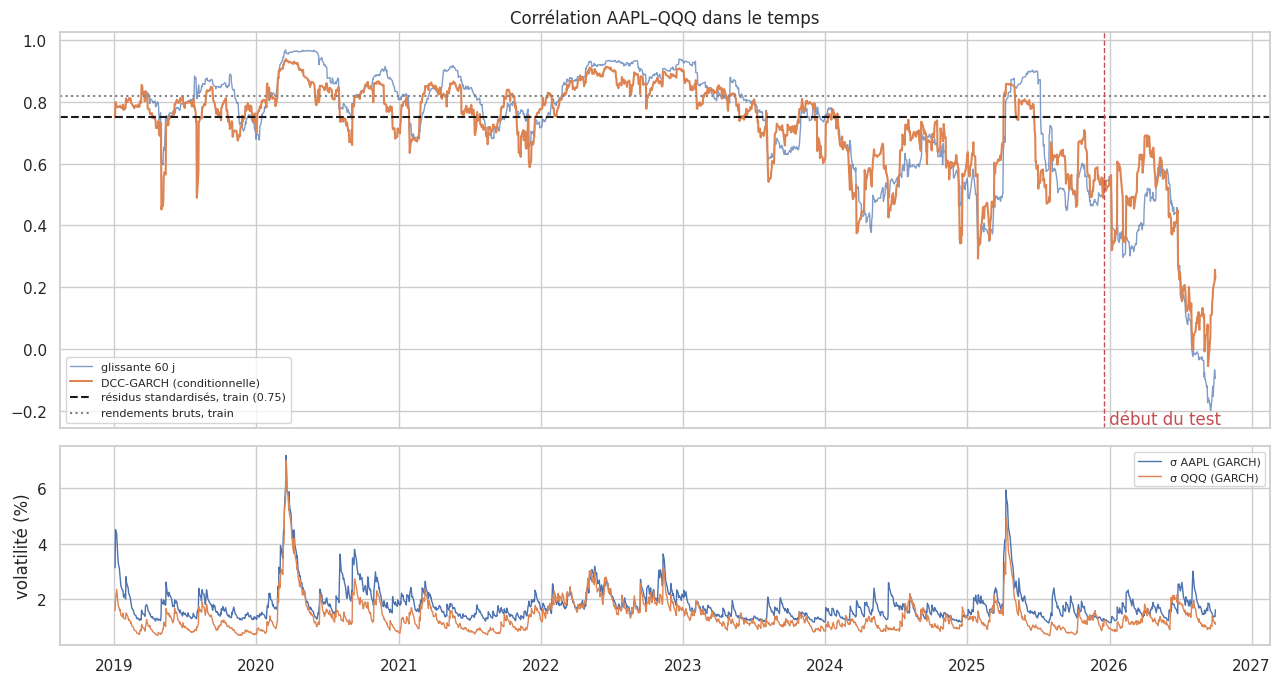

Corrélation de rang entre ρ_t (DCC) et la volatilité d'AAPL : 0.390 (p = 7.01e-72) → la corrélation augmente avec la volatilité (effet « crise : tout bouge ensemble »).
ρ_t DCC : min -0.056 | médiane 0.760 | max 0.939


In [122]:
# === 7.2 — Comparaison visuelle : constante / glissante 60 j / DCC ====================
roll60 = returns["AAPL"].rolling(60).corr(returns["QQQ"])
fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax[0].plot(roll60, lw=1, alpha=.7, label="glissante 60 j"); ax[0].plot(rho_dcc, lw=1.5, label="DCC-GARCH (conditionnelle)")
ax[0].axhline(Qbar[0, 1], color="k", ls="--", label=f"résidus standardisés, train ({Qbar[0, 1]:.2f})")
ax[0].axhline(returns.loc[returns.index <= train_end].corr().iloc[0, 1], color="gray", ls=":", label="rendements bruts, train")
ax[0].axvline(train_end, color="r", ls="--", lw=1); ax[0].text(train_end, ax[0].get_ylim()[0], " début du test", color="r", va="bottom")
ax[0].set_title("Corrélation AAPL–QQQ dans le temps"); ax[0].legend(fontsize=8, loc="lower left")
ax[1].plot(sig_a, lw=1, label="σ AAPL (GARCH)"); ax[1].plot(sig_q, lw=1, label="σ QQQ (GARCH)"); ax[1].set_ylabel("volatilité (%)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

common = pd.concat([rho_dcc, sig_a], axis=1, keys=["rho", "sig"]).dropna()
rs, ps = stats.spearmanr(common["rho"], common["sig"])
print(f"Corrélation de rang entre ρ_t (DCC) et la volatilité d'AAPL : {rs:.3f} (p = {ps:.2e}) → ", end="")
print("la corrélation augmente avec la volatilité (effet « crise : tout bouge ensemble »)." if rs > 0.1 else "pas de lien net corrélation–volatilité sur cet échantillon.")
print(f"ρ_t DCC : min {rho_dcc.min():.3f} | médiane {rho_dcc.median():.3f} | max {rho_dcc.max():.3f}")

### Application : le ratio de couverture dynamique
**Question pratique** : un gérant détient AAPL et veut se couvrir en vendant QQQ. Quelle quantité ? Le ratio optimal (minimisant la variance) est $\beta_t=\rho_t\,\sigma_{A,t}/\sigma_{Q,t}$. On compare, **sur le test uniquement**, le portefeuille couvert avec :
- un $\beta$ **statique** (régression sur le train),
- le $\beta_t$ **dynamique** du DCC (tous ses ingrédients sont connus la veille).

Critère : variance du rendement du portefeuille $r_A-\beta\,r_Q$ (plus faible = meilleure couverture), avec un Diebold-Mariano sur le carré des rendements couverts.

In [123]:
# === 7.2 — Couverture statique vs dynamique sur le TEST ================================
rA, rQ = returns["AAPL"] * 100, returns["QQQ"] * 100
beta_static = np.cov(rA[rA.index <= train_end], rQ[rQ.index <= train_end])[0, 1] / rQ[rQ.index <= train_end].var()
idx_te = Z.index[Z.index > train_end]
beta_dyn = (rho_dcc * sig_a / sig_q).reindex(idx_te)                      # β_t = ρ_t σ_A,t / σ_Q,t  (connu à t-1)
h_none, h_stat, h_dyn = rA.reindex(idx_te), rA.reindex(idx_te) - beta_static * rQ.reindex(idx_te), rA.reindex(idx_te) - beta_dyn * rQ.reindex(idx_te)
tab = pd.DataFrame({"variance des rendements (%²)": [h_none.var(), h_stat.var(), h_dyn.var()]},
                   index=["AAPL non couvert", f"couvert, β statique = {beta_static:.2f}", "couvert, β dynamique (DCC)"])
tab["réduction de variance"] = 1 - tab["variance des rendements (%²)"] / h_none.var()
display(tab.round(4))
dm, p = diebold_mariano(h_dyn.values, h_stat.values)
print(f"β dynamique : min {beta_dyn.min():.2f} | médiane {beta_dyn.median():.2f} | max {beta_dyn.max():.2f}")
print(f"Diebold-Mariano (β dynamique vs statique, carrés des rendements couverts) : DM = {dm:.3f}, p = {p:.3f} → {verdict(dm, p)}")
print("Lecture : la couverture dynamique n'a d'intérêt que si elle réduit significativement la variance par rapport au β fixe ; sinon la simplicité l'emporte.")
tab.to_csv(f"{OUT_DIR}/hedging_part7.csv")

,variance des rendements (%²),réduction de variance
AAPL non couvert,2.7538,0.0000
"couvert, β statique = 1.05",3.7203,-0.3509
"couvert, β dynamique (DCC)",2.6708,0.0301


β dynamique : min -0.11 | médiane 0.55 | max 0.99
Diebold-Mariano (β dynamique vs statique, carrés des rendements couverts) : DM = -4.830, p = 0.000 → significativement MEILLEUR
Lecture : la couverture dynamique n'a d'intérêt que si elle réduit significativement la variance par rapport au β fixe ; sinon la simplicité l'emporte.


## 7.3 — Événements, ruptures de régime et texte

**Objectif de l'énoncé** : relier des événements aux **ruptures observées**. Trois niveaux, du plus automatique au plus qualitatif :

1. **Détecter les ruptures sans connaître les événements** : modèle à **régimes de Markov** à deux états (calme / stress, avec une variance différente par état) sur les rendements d'AAPL. Les dates où l'on bascule vers l'état « stress » sont des ruptures de régime. *Usage descriptif* : les probabilités « lissées » utilisent tout l'échantillon (on regarde le passé avec le recul), ce n'est donc **pas** un signal de trading.
2. **Repérer les jours extrêmes** : plus grands résidus standardisés du GARCH (|z| élevé = choc inattendu *même compte tenu de la volatilité du moment*).
3. **Relier aux événements** : calendrier d'événements publics (ci-dessous) puis **rapprochement automatique** (± 4 jours calendaires) ; ce qui n'est pas expliqué est signalé « à documenter » plutôt que **inventé**.

La partie texte (FinBERT) vient ensuite, si vous fournissez un corpus.

Régime CALME : écart-type 1.31 %/jour | moyenne +0.172 % | durée moyenne 27 jours
Régime STRESS : écart-type 3.42 %/jour | moyenne -0.129 % | durée moyenne 7 jours
Part du temps en stress : 17.0%


,debut,fin,jours,rendement_cumule_pct,pire_jour_pct
0,2019-04-30,2019-05-14,11,-7.73,-5.99
1,2019-08-01,2019-08-15,11,-5.07,-5.38
2,2020-01-27,2020-02-04,7,0.17,-4.54
3,2020-02-21,2020-04-23,44,-15.24,-13.77
4,2020-07-23,2020-08-12,15,15.18,-4.66
5,2020-08-28,2020-10-13,32,-3.18,-8.34
6,2020-10-28,2020-11-06,8,1.95,-5.76
7,2021-01-04,2021-01-08,5,-0.48,-3.42
8,2021-01-20,2021-01-29,8,3.18,-3.81
9,2021-02-24,2021-03-10,11,-4.78,-4.26


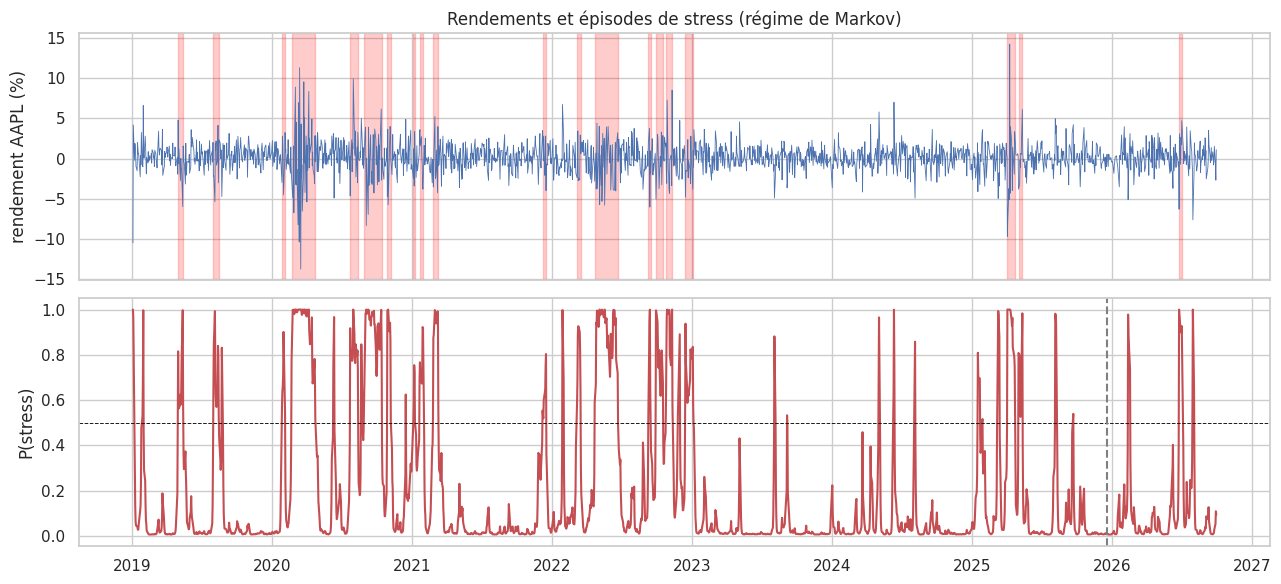

In [124]:
# === 7.3 — Régimes de Markov (calme / stress) sur les rendements d'AAPL ================
r_full = returns["AAPL"] * 100
try:
    ms = MarkovRegression(r_full, k_regimes=2, trend="c", switching_variance=True).fit(disp=False)
except Exception:
    ms = MarkovRegression(r_full, k_regimes=2, trend="c", switching_variance=True).fit(search_reps=10, disp=False)
par = ms.params
s2 = np.array([par["sigma2[0]"], par["sigma2[1]"]]); stress = int(np.argmax(s2)); calm = 1 - stress
p_stress = ms.smoothed_marginal_probabilities[stress]
dur = np.asarray(ms.expected_durations)
print(f"Régime CALME : écart-type {np.sqrt(s2[calm]):.2f} %/jour | moyenne {par[f'const[{calm}]']:+.3f} % | durée moyenne {dur[calm]:.0f} jours")
print(f"Régime STRESS : écart-type {np.sqrt(s2[stress]):.2f} %/jour | moyenne {par[f'const[{stress}]']:+.3f} % | durée moyenne {dur[stress]:.0f} jours")
print(f"Part du temps en stress : {(p_stress > 0.5).mean():.1%}")

# Épisodes de stress (≥ 5 jours consécutifs avec probabilité > 0.5 ; les épisodes plus courts sont du bruit)
s_bin = (p_stress > 0.5).astype(int); grp = (s_bin != s_bin.shift()).cumsum()
eps = []
for _, g_ in s_bin.groupby(grp):
    if g_.iloc[0] == 1 and len(g_) >= 5:
        d0, d1 = g_.index[0], g_.index[-1]
        eps.append(dict(debut=d0, fin=d1, jours=len(g_), rendement_cumule_pct=float(r_full.loc[d0:d1].sum()), pire_jour_pct=float(r_full.loc[d0:d1].min())))
episodes = pd.DataFrame(eps)
display(episodes.round(2))

fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
ax[0].plot(r_full, lw=.6); ax[0].set_ylabel("rendement AAPL (%)"); ax[0].set_title("Rendements et épisodes de stress (régime de Markov)")
for _, e in episodes.iterrows(): ax[0].axvspan(e.debut, e.fin, color="red", alpha=.2)
ax[1].plot(p_stress, color="C3"); ax[1].axhline(0.5, color="k", ls="--", lw=.7); ax[1].set_ylabel("P(stress)"); ax[1].axvline(train_end, color="gray", ls="--")
plt.tight_layout(); plt.show()

In [125]:
# === 7.3 — Jours extrêmes, calendrier d'événements et rapprochement ====================
# Calendrier d'événements PUBLICS. Confiance « haute » = date et ampleur bien établies ; « à sourcer » = date approximative issue de la presse financière :
# À VÉRIFIER ET CITER avec une source avant de l'utiliser dans le rapport.
EVENTS = pd.DataFrame([
    ("2019-01-03", "Apple abaisse sa prévision de chiffre d'affaires (AAPL ≈ -10 %)", "haute"),
    ("2020-03-16", "Krach COVID-19 : pire séance (AAPL ≈ -13 %)", "haute"),
    ("2020-03-24", "Rebond COVID après l'annonce d'un plan de relance américain", "haute"),
    ("2020-09-03", "Vente massive des valeurs technologiques (AAPL ≈ -8 %)", "haute"),
    ("2022-11-10", "Inflation américaine plus faible que prévu : forte hausse du Nasdaq (≈ +7 %)", "haute"),
    ("2024-06-11", "Après la conférence développeurs, AAPL ≈ +7 % (annonces d'IA)", "à sourcer"),
    ("2024-08-05", "Dénouement du carry trade sur le yen : chute mondiale, VIX en forte hausse", "haute"),
    ("2025-04-04", "Droits de douane américains : pire séance de l'année pour le Nasdaq-100", "haute"),
    ("2025-04-09", "Pause de 90 jours des droits de douane : meilleure séance (Nasdaq-100 ≈ +12 %, AAPL ≈ +15 %)", "haute"),
    ("2026-03-27", "Nasdaq-100 en zone de correction (hausse des rendements obligataires, tensions géopolitiques)", "à sourcer"),
    ("2026-03-31", "Fort rebond du Nasdaq (> +3 %) après la correction de fin mars", "à sourcer"),
    ("2026-06-09", "Rotation hors des valeurs IA / semi-conducteurs : Nasdaq-100 ≈ -3 %", "à sourcer"),
    ("2026-07-31", "Nasdaq-100 en zone de correction fin juillet", "à sourcer"),
    ("2026-08-04", "Rebond du Nasdaq-100 (≈ +3 %) après résultats IA et baisse des rendements", "à sourcer"),
], columns=["date", "evenement", "confiance"])
EVENTS["date"] = pd.to_datetime(EVENTS["date"])

def nearest_event(d, tol_days=4):
    """Événement du calendrier le plus proche de la date d (± tol_days jours calendaires), sinon None."""
    gap = (EVENTS["date"] - d).abs().dt.days
    return EVENTS.loc[gap.idxmin(), "evenement"] if gap.min() <= tol_days else None

ext = z_a.abs().sort_values(ascending=False).head(10).index.sort_values()
ext_tab = pd.DataFrame({"rendement AAPL (%)": r_full.reindex(ext), "z GARCH": z_a.reindex(ext),
                        "P(stress)": p_stress.reindex(ext), "événement rapproché": [nearest_event(d) or "⚠ à documenter par l'équipe" for d in ext]})
display(ext_tab.round(2))
if len(episodes):
    ep_tab = episodes.assign(**{"événement rapproché (début d'épisode)": [nearest_event(d) or "⚠ à documenter par l'équipe" for d in episodes["debut"]]})
    display(ep_tab[["debut", "fin", "jours", "rendement_cumule_pct", "événement rapproché (début d'épisode)"]].round(2))
n_match = int(sum(nearest_event(d) is not None for d in ext)); print(f"{n_match}/{len(ext)} jours extrêmes rapprochés d'un événement du calendrier ; les autres sont à documenter (chercher l'actualité de la date).")

,rendement AAPL (%),z GARCH,P(stress),événement rapproché
Date,,,,
2019-05-13,-5.99,-3.45,1.00,⚠ à documenter par l'équipe
2020-07-31,9.96,5.22,1.00,⚠ à documenter par l'équipe
2020-09-03,-8.34,-3.73,1.00,Vente massive des valeurs technologiques (AAPL...
2022-01-28,6.75,4.45,1.00,⚠ à documenter par l'équipe
2023-08-04,-4.92,-3.94,0.88,⚠ à documenter par l'équipe
2024-06-11,7.01,4.83,1.00,"Après la conférence développeurs, AAPL ≈ +7 % ..."
2025-04-03,-9.70,-6.04,1.00,Droits de douane américains : pire séance de l...
2026-02-12,-5.13,-3.48,0.98,⚠ à documenter par l'équipe
2026-06-25,-6.31,-4.40,1.00,⚠ à documenter par l'équipe


,debut,fin,jours,rendement_cumule_pct,événement rapproché (début d'épisode)
0,2019-04-30,2019-05-14,11,-7.73,⚠ à documenter par l'équipe
1,2019-08-01,2019-08-15,11,-5.07,⚠ à documenter par l'équipe
2,2020-01-27,2020-02-04,7,0.17,⚠ à documenter par l'équipe
3,2020-02-21,2020-04-23,44,-15.24,⚠ à documenter par l'équipe
4,2020-07-23,2020-08-12,15,15.18,⚠ à documenter par l'équipe
5,2020-08-28,2020-10-13,32,-3.18,⚠ à documenter par l'équipe
6,2020-10-28,2020-11-06,8,1.95,⚠ à documenter par l'équipe
7,2021-01-04,2021-01-08,5,-0.48,⚠ à documenter par l'équipe
8,2021-01-20,2021-01-29,8,3.18,⚠ à documenter par l'équipe
9,2021-02-24,2021-03-10,11,-4.78,⚠ à documenter par l'équipe


4/10 jours extrêmes rapprochés d'un événement du calendrier ; les autres sont à documenter (chercher l'actualité de la date).


### Sentiment textuel : embeddings et FinBERT (optionnel)
**Idée de l'énoncé** : un modèle de langage de type **FinBERT** (BERT entraîné sur des textes financiers) transforme chaque titre d'actualité en un score de sentiment (positif − négatif) ; on agrège par jour, puis on regarde si le texte **précède ou accompagne** les ruptures.

**Mode d'emploi** : placer un fichier `../data/news.csv` avec deux colonnes `date` (AAAA-MM-JJ) et `headline` (un titre par ligne, sur AAPL / Nasdaq). Si `transformers` + `torch` sont installés et qu'Internet est disponible, **FinBERT** est utilisé ; sinon un **lexique minimal** de repli est appliqué (le notebook l'indique : le sentiment est alors grossier). Sans fichier, cette partie est ignorée.

**Précautions** : (1) un titre publié après la clôture concerne le jour *suivant* → on attribue le texte au jour de bourse suivant si l'heure est connue ; (2) avec peu de titres les corrélations sont **non significatives** — le notebook avertit en dessous de 30 jours couverts ; (3) le sentiment du même jour est en partie *la conséquence* du rendement (les journalistes commentent le mouvement) ; seule la corrélation avec le rendement **du lendemain** a une valeur prédictive.

In [126]:
# === 7.3 — Sentiment des actualités (FinBERT si disponible, sinon lexique) ==============
POS = {"beat", "beats", "surge", "surges", "rally", "gain", "gains", "record", "strong", "growth", "upgrade", "profit", "bullish", "rebound", "soar", "soars", "jump", "jumps", "rise", "rises", "boost"}
NEG = {"miss", "misses", "plunge", "plunges", "crash", "fall", "falls", "drop", "drops", "loss", "losses", "weak", "downgrade", "bearish", "tariff", "tariffs", "selloff", "sell-off", "lawsuit", "recession", "cut", "cuts", "warning", "fear", "slump", "slide"}

def score_lexicon(texts):
    out = []
    for t in texts:
        w = re.findall(r"[a-zA-Z\-]+", t.lower()); p, n = sum(x in POS for x in w), sum(x in NEG for x in w)
        out.append((p - n) / max(p + n, 1))
    return np.array(out)

def score_finbert(texts):
    from transformers import pipeline                      # nécessite transformers + torch + accès au modèle ProsusAI/finbert
    clf = pipeline("text-classification", model="ProsusAI/finbert", top_k=None, truncation=True)
    res_ = clf(list(texts), batch_size=16)
    return np.array([{d["label"].lower(): d["score"] for d in o}.get("positive", 0) - {d["label"].lower(): d["score"] for d in o}.get("negative", 0) for o in res_])

def score_texts(texts):
    try: return score_finbert(texts), "FinBERT (ProsusAI/finbert)"
    except Exception as e: return score_lexicon(texts), f"lexique minimal de repli (FinBERT indisponible : {type(e).__name__})"

sent_daily = None
if os.path.exists(NEWS_PATH):
    news = pd.read_csv(NEWS_PATH); news["date"] = pd.to_datetime(news["date"]); news = news.dropna(subset=["headline"])
    news["sent"], backend = score_texts(news["headline"].astype(str).tolist())
    sent_daily = news.groupby("date")["sent"].mean().reindex(dataset.index)
    print(f"Corpus : {len(news)} titres, {int(sent_daily.notna().sum())} jours de bourse couverts | méthode : {backend}")
    if sent_daily.notna().sum() < 30: print("⚠ moins de 30 jours couverts : les résultats ci-dessous sont indicatifs seulement (puissance statistique très faible).")
else:
    pd.DataFrame(columns=["date", "headline"]).to_csv(f"{NEWS_PATH.replace('news.csv', 'news_template.csv')}", index=False)
    print("Aucun corpus (../data/news.csv) : partie texte ignorée. Un gabarit vide a été écrit dans ../data/news_template.csv (colonnes date, headline).")

Aucun corpus (../data/news.csv) : partie texte ignorée. Un gabarit vide a été écrit dans ../data/news_template.csv (colonnes date, headline).


In [127]:
# === 7.3 — Le sentiment précède-t-il / accompagne-t-il les rendements et les ruptures ? ======
if sent_daily is not None and sent_daily.notna().sum() >= 5:
    d_ = pd.concat([sent_daily.rename("s"), r_t.rename("r"), r_t.shift(-1).rename("r_next"), r_t.abs().shift(-1).rename("absr_next")], axis=1).dropna()
    print(f"corrélation sentiment(t) ↔ rendement(t)   : {d_['s'].corr(d_['r']):+.3f}  (accompagne : en partie une conséquence du mouvement)")
    print(f"corrélation sentiment(t) ↔ rendement(t+1) : {d_['s'].corr(d_['r_next']):+.3f}  (valeur prédictive éventuelle)")
    print(f"corrélation |sentiment(t)| ↔ |rendement(t+1)| : {d_['s'].abs().corr(d_['absr_next']):+.3f}  (le texte annonce-t-il de l'agitation ?)")
    # Étude d'événement : jours à sentiment extrême (quartile supérieur de |s|) vs autres jours avec actualités
    thr = d_["s"].abs().quantile(0.75); hi_, lo_ = d_[d_["s"].abs() >= thr], d_[d_["s"].abs() < thr]
    if len(hi_) > 2 and len(lo_) > 2:
        t, p = stats.ttest_ind(r_t.abs().shift(-1).reindex(hi_.index).dropna(), r_t.abs().shift(-1).reindex(lo_.index).dropna(), equal_var=False)
        print(f"|rendement| du lendemain : {r_t.abs().shift(-1).reindex(hi_.index).mean():.4f} (sentiment extrême) vs {r_t.abs().shift(-1).reindex(lo_.index).mean():.4f} (autres) | Welch t = {t:.2f}, p = {p:.3f}")
    neg_days = sent_daily[sent_daily <= sent_daily.quantile(0.2)].dropna().index
    in_stress = (p_stress.reindex(neg_days).dropna() > 0.5).mean(); base = (p_stress > 0.5).mean()
    print(f"Part des jours à sentiment très négatif situés en régime de stress : {in_stress:.1%} (référence : {base:.1%} du temps en stress)")
else:
    print("(pas de corpus exploitable : analyse du sentiment ignorée)")

(pas de corpus exploitable : analyse du sentiment ignorée)


### Conclusion de la partie 7 (à rédiger avec VOS chiffres)

| Extension | Ce qu'il faut rapporter | Verdict honnête typique |
|---|---|---|
| **Exogènes** | ADF des variables transformées ; p-values de Granger (avec Bonferroni) ; ablation Diebold-Mariano par réseau | si Granger et DM ne sont pas significatifs : « pas d'information exploitable à ces horizons » |
| **Corrélation dynamique** | paramètres $a,b$ du DCC ; AIC DCC vs constante ; lien ρ–volatilité ; réduction de variance de la couverture + DM | la corrélation varie bien dans le temps (visible sur le graphique), mais le gain de couverture peut être modeste |
| **Événements** | régimes de Markov (volatilités, durées) ; épisodes de stress ; part des jours extrêmes expliqués par le calendrier ; sentiment si un corpus a été fourni | les plus gros chocs correspondent à des événements macro/entreprise identifiables ; le reste reste à documenter |

**Limites à écrire** : calendrier d'événements construit à partir de connaissances publiques et de la presse (à sourcer) ; régimes de Markov estimés sur tout l'échantillon (usage descriptif) ; DCC à paramètres communs (un seul couple $a,b$) ; texte : corpus limité, lexique de repli grossier, FinBERT non entraîné spécifiquement sur AAPL ; plusieurs hypothèses testées → risque de faux positifs.